In [12]:
import pickle

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pickle
import scipy.signal as sp

In [3]:
t= np.arange(0,4*np.pi, 0.1)
x1 = np.sin(t)
x2 = np.cos(t)
x3 = -np.sin(t)
x4 = t**2
C = np.corrcoef([x1,x2,x3,x4])


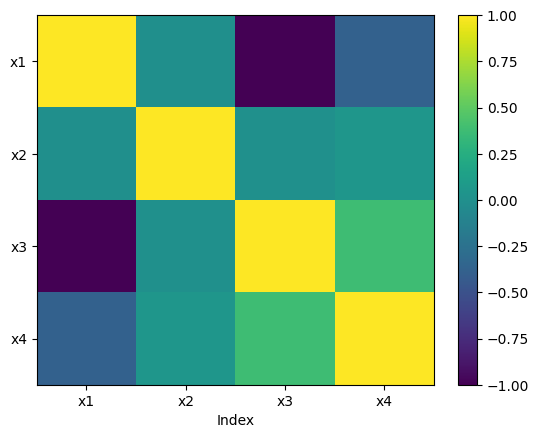

In [4]:
plt.imshow(C, aspect="auto")
plt.xlabel("Index")
plt.xticks(range(0,4), ["x1","x2","x3","x4"])
plt.yticks(range(0,4), ["x1","x2","x3","x4"])
plt.colorbar()
plt.show()


In [11]:
# Data Cleaning
frame = pd.DataFrame(np.random.randn(4,3), index=[1,2,4,7], columns=["A","B","C"])
# create NaNs "artificially" by expanding the number of
# rows of the data frame
frameWithNaNs = frame.reindex(np.arange(1,8,dtype=int))
replacedNaNs = frameWithNaNs.replace({np.nan:0.0})

print(frameWithNaNs)
print(50*"=")
print(replacedNaNs)

          A         B         C
1  1.433101 -0.265334  2.016816
2  0.994630 -0.263591  0.222625
3       NaN       NaN       NaN
4 -1.035349  2.282462 -0.180026
5       NaN       NaN       NaN
6       NaN       NaN       NaN
7 -0.641204 -0.122170 -1.480030
          A         B         C
1  1.433101 -0.265334  2.016816
2  0.994630 -0.263591  0.222625
3  0.000000  0.000000  0.000000
4 -1.035349  2.282462 -0.180026
5  0.000000  0.000000  0.000000
6  0.000000  0.000000  0.000000
7 -0.641204 -0.122170 -1.480030


In [14]:
# Tracking and eliminating duplicates
x0 = [1,2,3,4,5,6,7,8,9]
x1 = [1,3,1,4,4,1,2,5,1]
x2 = [1,3,1,4,4,3,2,5,5]
x3 = [1,3,3,3,1,2,4,5,1]

frame = pd.DataFrame([x0,x1,x2,x1,x3])
frame.duplicated()

0    False
1    False
2    False
3     True
4    False
dtype: bool

In [16]:
# Application of Normalization (Pendiente)
data = pickle.load(open("EX03EngineExt.pickle", "rb"))

FileNotFoundError: [Errno 2] No such file or directory: 'EX03EngineExt.pickle'

In [17]:
# Filtering of Data
x = 3 + 0.5 * np.random.randn(500)
filtered_x = []
window = 15

for i in range(0, len(x)-window):
    filtered_x.append(np.mean(x[i:i+window]))

Text(0, 0.5, 'x')

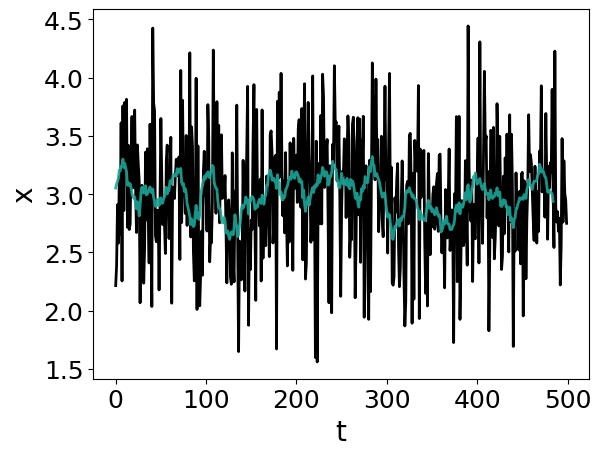

In [18]:
plt.plot(x, "k", linewidth=2.0)
plt.plot(filtered_x, "-", color=[0.1,0.65,0.6], linewidth=2.0, alpha = 0.9)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlabel("t", fontsize=20)
plt.ylabel("x", fontsize=20)


Text(0, 0.5, 'x')

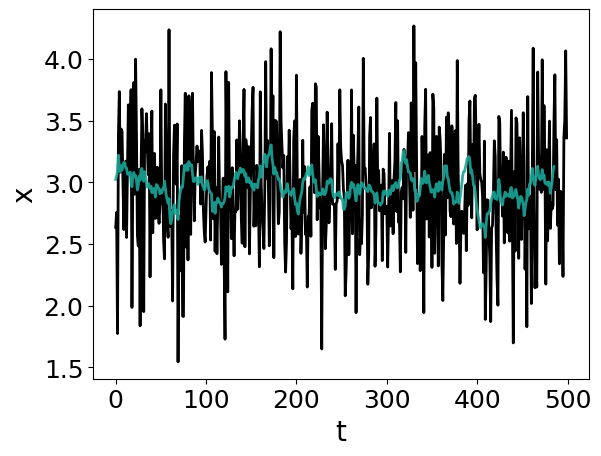

In [23]:
x = 3 + 0.5 * np.random.randn(500)
window = 15
filtered_x = np.convolve(x, np.array(np.ones(window)/window), mode="valid")

plt.plot(x, "k", linewidth=2.0)
plt.plot(filtered_x, "-", color=[0.1,0.65,0.6], linewidth=2.0, alpha = 0.9)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlabel("t", fontsize=20)
plt.ylabel("x", fontsize=20)


Text(0, 0.5, 'x')

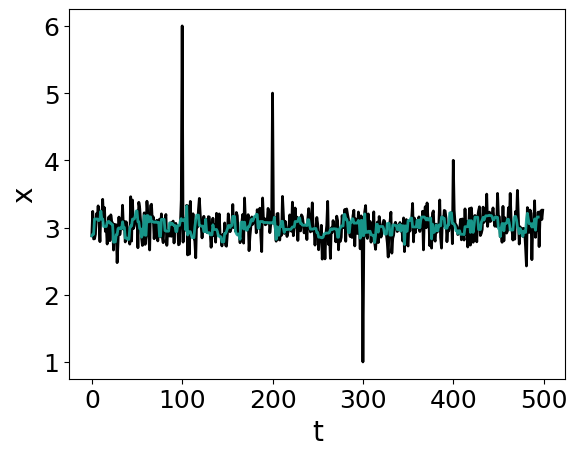

In [3]:
x = 3 + 0.2 * np.random.randn(500)
x[100] = 6
x[200] = 5
x[300] = 1
x[400] = 4
filtered_x = []

for i in range(0, len(x)-5):
    filtered_x.append(np.median(x[i:i+5]))

plt.plot(x, "k", linewidth=2.0)
plt.plot(filtered_x, "-", color=[0.1,0.65,0.6], linewidth=2.0, alpha = 0.9)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlabel("t", fontsize=20)
plt.ylabel("x", fontsize=20)


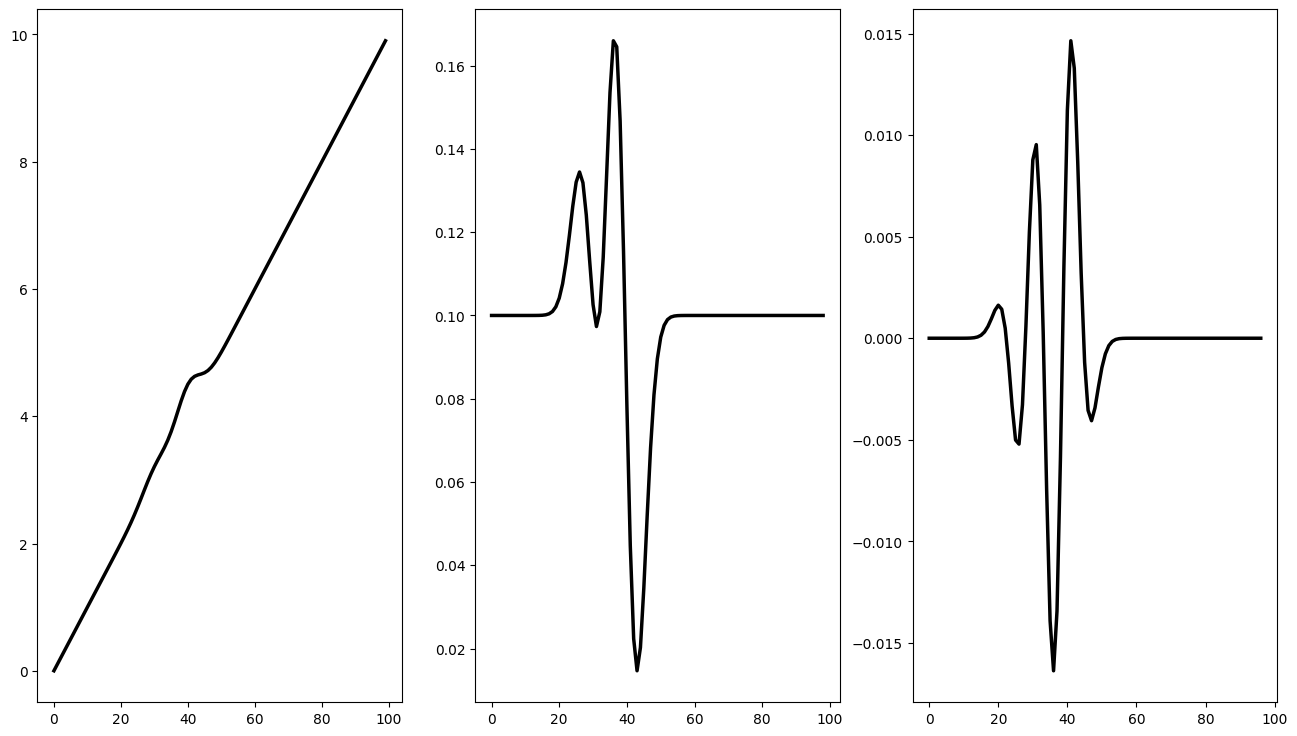

In [6]:
# Transformations: Differentiation of Data

x = np.arange(0,100)
y1 = 0.5 * np.exp(-(x-40)**2/25)
y2 = 0.2 * np.exp(-(x-30)**2/25)
y3 = y1 + y2 + 0.1*x

fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(16,9))
ax1.plot(x,y3,"k", linewidth=2.5)
ax2.plot(np.diff(y3),"k", linewidth=2.5)
ax3.plot(np.diff(y3,3),"k", linewidth=2.5)


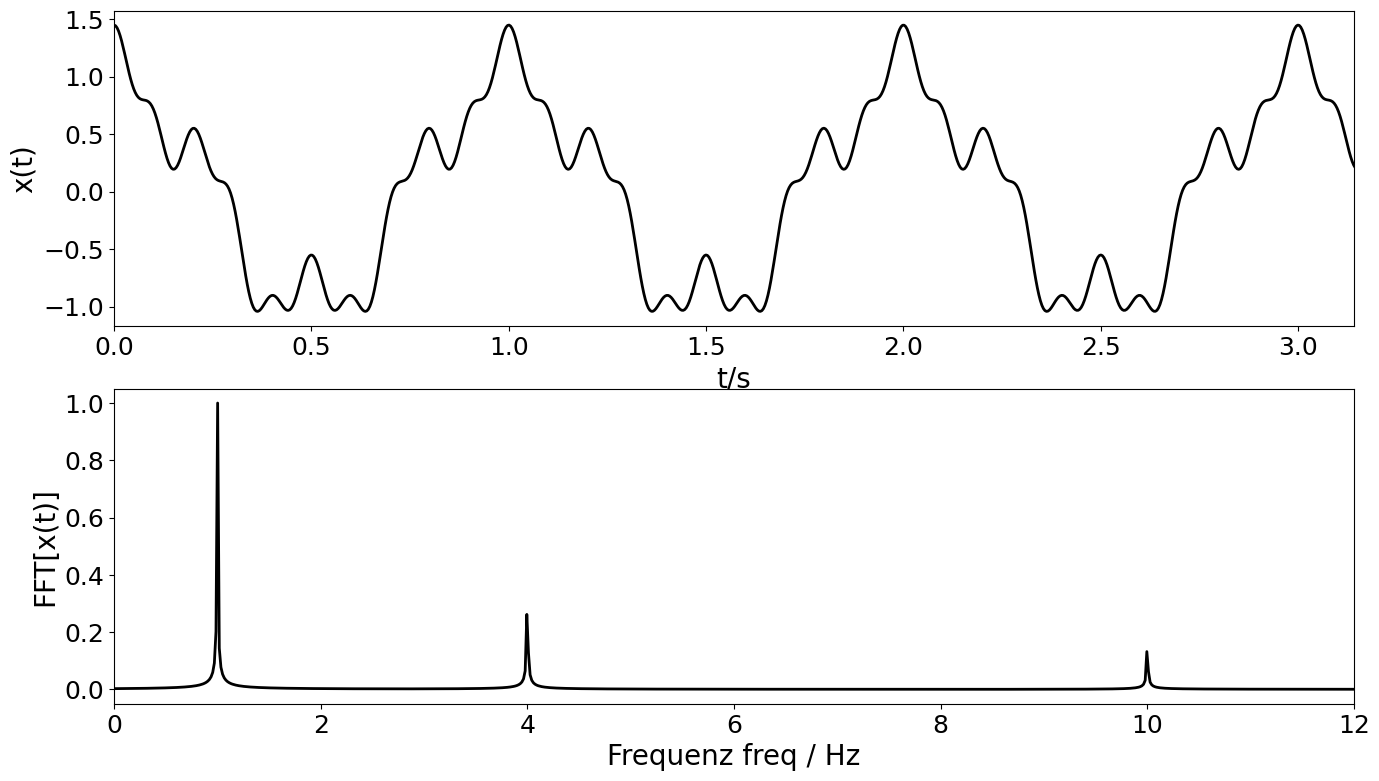

In [8]:
# Fast Fourier Transform
# Definición de las frecuencias en Hz
nu1 = 1
nu2 = 4
nu3 = 10

A1 = 1
A2 = 0.3
A3 = 0.15

# Datos de ejemplo con estas frecuencias
final_t = 20 * np.pi
dt = final_t / 2**14
t = np.arange(0, final_t, dt) # in s
x = A1 * np.exp(1j * 2 * np.pi * nu1 * t) \
    + A2 * np.exp(1j * 2 * np.pi * nu2 * t) \
    + A3 * np.exp(1j * 2 * np.pi * nu3 * t)

# Cálculo de la FFT
fft = np.fft.fft(x)
freq = np.fft.fftfreq(x.size, d=dt)

# Normalización
fft = np.abs(fft)
fft /= np.max(fft)

# Representación
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16,9))

ax1.plot(t, np.real(x), "k", linewidth=2.0)
ax1.set_xlabel("t/s", fontsize=20)
ax1.set_ylabel("x(t)", fontsize=20)
ax1.set_xlim([0, np.pi])
ax1.tick_params("both", labelsize=18)
ax1.tick_params("both", labelsize=18)

ax2.plot(freq[0:8191], fft[0:8191], "k", linewidth=2)

ax2.set_xlim([0, 12])
ax2.set_xlabel("Frequenz freq / Hz", fontsize=20)
ax2.set_ylabel("FFT[x(t)]", fontsize=20)
ax2.tick_params("both", labelsize=18)
ax2.tick_params("both", labelsize=18)


In [ ]:
for i in range(0, 500):
    fft = np.fft.fft( (newData[i] - np.mean(newData[i])) / np.sum(newData[i]))
    fft = np.abs(fft)
    fft /= np.max(fft)
    if fft[8]>0.015:
        myColor = 'r'
    else:
        myColor = 'k'
    plt.plot(fft, color=myColor, alpha=0.2)

In [13]:
# Wavelet Transformation
final_t = 5 * np.pi
dt = final_t / 2**14
t = np.array(np.arange(0, final_t, dt))
x = np.cos(2 * np.pi * 1. * t) + 3 * np.exp(-1*(t-1))
widths = 1 * np.arange(10,200,2)
cwtmatr = sp.cwt(x, sp.ricker, widths)

plt.imshow(np.real(cwtmatr), cmap="nipy_spectral", vmin=0, vmax=np.max(np.real(cwtmatr)), aspect="auto")

AttributeError: module 'scipy.signal' has no attribute 'cwt'